# Module 7 — High-Frequency Trading: run the whole module

**How to use:**
- **Run all** to run the full module in order, or run a single cell to run one step.
- Each cell runs one notebook in full and shows all its tables and charts here.
- Every notebook also runs on its own: open it from `notebooks/` and run all.

**Order matters:** Task 2 reads the files Task 1 saves in `outputs/task1/`; the workbook reads both.

| Step | Notebook | Status |
| --- | --- | --- |
| 0. Data check | `helpers/m07_data.py` | Built |
| 1. Task 1 — Short-horizon direction prediction | `notebooks/m07_task1_direction.ipynb` | Built |
| 2. Task 2 — Model probability into trading signal | `notebooks/m07_task2_signal.ipynb` | Built |
| Final. Output workbook | `helpers/m07_final_output.py` → `outputs/FINAL_M7_module_output.xlsx` | Built |

## Setup
Moves into the module folder so the paths below work, both locally and in Google Colab.
- **Colab:** upload the whole unzipped project folder (any name) to Google Drive; the cell below finds it. Then run all cells.

In [1]:
import os
import sys
from pathlib import Path

# ---- Find the project folder: any folder name works, on your computer or in Google Colab ----
# The project folder is the one holding run_novafin.ipynb and data/.
IN_COLAB = "google.colab" in sys.modules
is_project = lambda p: (p / "run_novafin.ipynb").exists() and (p / "data").is_dir()
places = [p for p in [Path.cwd(), *Path.cwd().parents] if is_project(p)]
if IN_COLAB and not places:                                 # Colab starts outside the project: look in /content, then in Google Drive
    for base in [Path("/content"), Path("/content/drive/MyDrive")]:
        if "drive" in base.parts:
            from google.colab import drive
            drive.mount("/content/drive")                   # asks for access to your Google Drive
        for depth in ["", "*/", "*/*/", "*/*/*/"]:
            places += [f.parent for f in sorted(base.glob(depth + "run_novafin.ipynb")) if is_project(f.parent)]
        if places:
            break
if not places:
    raise FileNotFoundError("Project folder not found: unzip the whole project and keep run_novafin.ipynb, data/ and the module folders together (see HOW_TO_RUN.md).")
PROJECT_ROOT = places[0]
os.chdir(PROJECT_ROOT / "module_07_hft")                  # the paths below start from the module folder
print("Working folder:", Path.cwd().name)

Working folder: module_07_hft


## 0. Data check
Is `nova_hft_orderbook.csv` complete and clean? Rows, missing values, days, stocks, class shares, that the label is built from `Future_Return_100ms` (so it is never an input), and the day split.

In [2]:
%run helpers/m07_data.py

rows: 120000
missing_values: 0
trading_days: 20
stocks: 10
event_types: {'LIMIT_ORDER': 57473, 'MARKET_ORDER': 32406, 'CANCEL': 30121}
class_share: {'DOWN': 0.419, 'UP': 0.417, 'NO_MOVE': 0.164}
mid_price_matches_bid_ask: True
future_return_equals_future_price_over_mid: True
leakage_columns_in_features: []
split_rows_train_tune_test: (84054, 18070, 17876)


## 1. Task 1 — Short-horizon direction prediction
Runs `notebooks/m07_task1_direction.ipynb` (about 3 minutes):
- explores the order book on the 14 training days;
- chooses 15 inputs; compares OBI alone, logistic regression, random forest and LightGBM;
- tests on 3 unseen days whether any model beats OBI alone;
- saves `outputs/task1/FINAL_M7_T1_direction_predictions.csv` for Task 2.

Outputs go to: module_07_hft/outputs/task1


rows: 120000
missing_values: 0
trading_days: 20
stocks: 10
event_types: {'LIMIT_ORDER': 57473, 'MARKET_ORDER': 32406, 'CANCEL': 30121}
class_share: {'DOWN': 0.419, 'UP': 0.417, 'NO_MOVE': 0.164}
mid_price_matches_bid_ask: True
future_return_equals_future_price_over_mid: True
leakage_columns_in_features: []
split_rows_train_tune_test: (84054, 18070, 17876)
UP      : next move from +1.20 to +27.93 bps; typical size 4.65 bps
DOWN    : next move from -31.62 to -1.20 bps; typical size 4.79 bps
NO_MOVE : next move from -1.20 to +1.20 bps; typical size 0.59 bps
Typical spread 1.14 bps; typical move 3.93 bps (₹3,932 per ₹1 crore)



Split (M7-04): train 84,054 events (days 1–14), tune 18,070 (15–17), test 17,876 (18–20, used once)


84,054 training events; 27 tests; line 0.05 ÷ 27 = 0.0019


Input,p,AUC UP vs DOWN,AUC NO_MOVE vs move,Rank correlation with next move,"Cramér's V (0 = no link, 1 = perfect)",Passes the line,Meaningful (AUC ≥ 0.03 from 0.5)
OBI_3Level,0.0000,0.786,0.511,+0.515,—,Yes,Yes
OBI_Level1,0.0000,0.786,0.512,+0.515,—,Yes,Yes
Microprice_gap,0.0000,0.782,0.515,+0.508,—,Yes,Yes
OBI_L2,0.0000,0.781,0.511,+0.504,—,Yes,Yes
OBI_L3,0.0000,0.770,0.510,+0.483,—,Yes,Yes
Bid_Size_1,0.0000,0.738,0.517,+0.425,—,Yes,Yes
Ask_Size_1,0.0000,0.273,0.500,-0.406,—,Yes,Yes
OFI,0.0000,0.638,0.502,+0.242,—,Yes,Yes
Signed_volume,0.0000,0.580,0.501,+0.139,—,Yes,Yes
Signed_volume_5,0.0000,0.568,0.502,+0.123,—,Yes,Yes


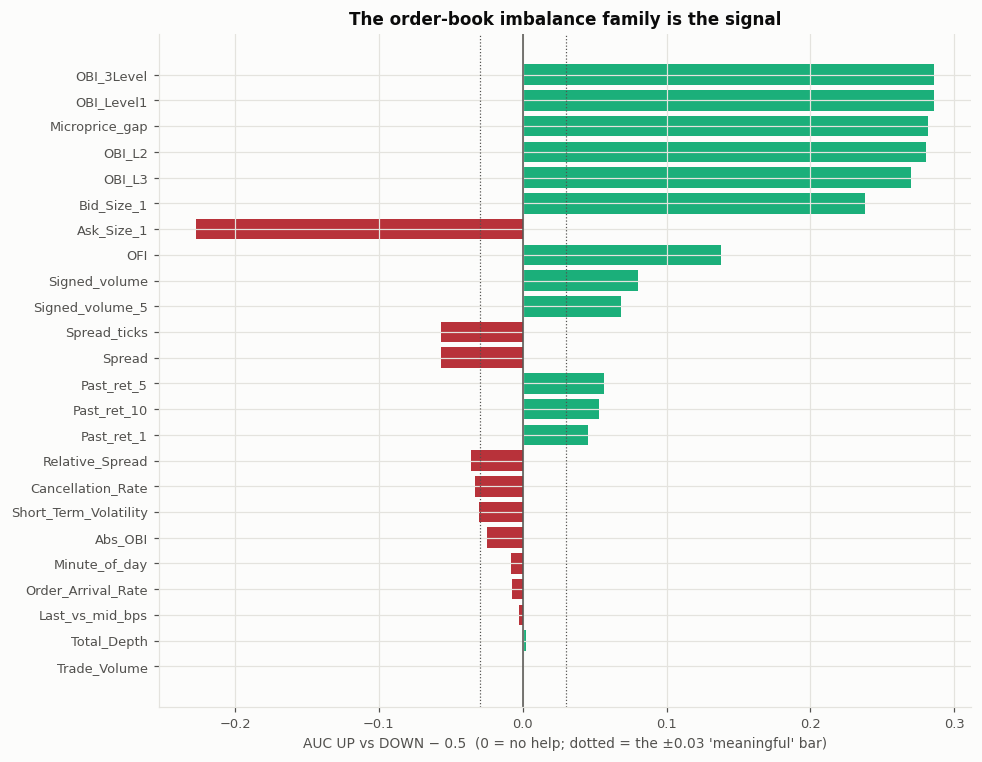

,OBI_Level1,OBI_3Level,OBI_L2,OBI_L3,Microprice_gap,OFI,Signed_volume,Signed_volume_5,Past_ret_1
OBI_Level1,1.00,0.99,0.96,0.92,0.98,0.48,0.27,0.23,0.16
OBI_3Level,0.99,1.00,0.98,0.95,0.97,0.47,0.27,0.23,0.16
OBI_L2,0.96,0.98,1.00,0.90,0.95,0.45,0.26,0.23,0.16
OBI_L3,0.92,0.95,0.90,1.00,0.91,0.43,0.25,0.22,0.15
Microprice_gap,0.98,0.97,0.95,0.91,1.00,0.44,0.26,0.24,0.17
OFI,0.48,0.47,0.45,0.43,0.44,1.00,0.12,-0.03,0.01
Signed_volume,0.27,0.27,0.26,0.25,0.26,0.12,1.00,0.44,0.04
Signed_volume_5,0.23,0.23,0.23,0.22,0.24,-0.03,0.44,1.00,0.06
Past_ret_1,0.16,0.16,0.16,0.15,0.17,0.01,0.04,0.06,1.00


OBI levels 1–3, OBI over 3 levels and the microprice gap correlate 0.90–0.99: one signal measured several ways.


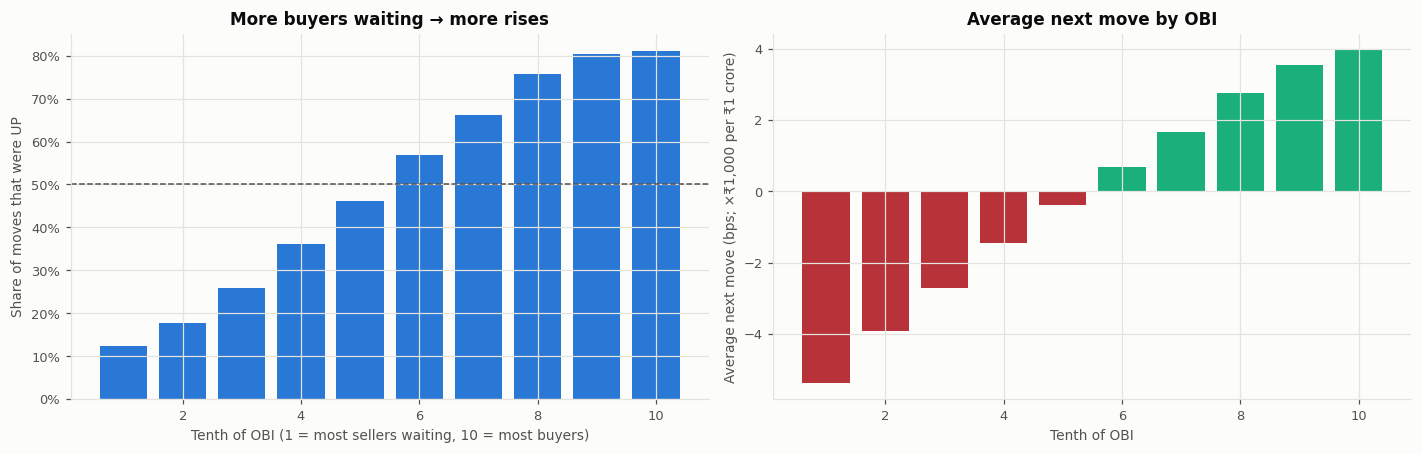

UP share of moves, by OBI third and the last trade's side:


Trade_Side,BUY,SELL
OBI_Level1,,
fewer buyers,21.1%,19.3%
balanced,53.3%,49.7%
more buyers,78.2%,77.6%


UP share by trade side and trade size (moves only):


Trade_Volume,small,medium,large
Trade_Side,,,
BUY,57.4%,57.9%,57.5%
SELL,41.8%,41.5%,41.8%


Time of day within each stock (line 0.05 ÷ 10 = 0.005): smallest p 0.009 (NOVA05); passing: 0
Stocks' minute-to-minute price changes move together: average correlation 0.51


Tuning-day AUC: own OBI 0.7795; own OBI + rest-of-market OBI 0.7795 → the market adds nothing


... (13 outputs left out)

Day,Logistic regression,OBI alone,Gain
28 Jan,0.789,0.779,+0.010
29 Jan,0.792,0.784,+0.009
30 Jan,0.793,0.782,+0.012


Logistic regression beats OBI alone in 10 of 10 stocks and 3 of 3 days; AUC by stock 0.774–0.806


Shuffled labels: AUC 0.542 on average (95% range 0.417–0.672); real model 0.788; p = 0.0099


Model,Tells rises from falls (test AUC; higher = better),Honest percentages (log-loss; lower = better),Beats the simple balance rule beyond chance?,Learned noise? (training − test AUC),Can you see why it predicts?,Training time,Chosen?
OBI alone,0.781,0.917,—,+0.005,Yes: one number,Instant,
Logistic regression,0.791,0.908,Yes (+0.010; range +0.0083 to +0.0122),+0.003,Yes: one weight per input (step 6b),About 1 second,Yes
Random forest,0.789,0.910,Yes (+0.008; range +0.0058 to +0.0095),+0.043,"Partly: 300 trees, only importance scores",About a minute,
LightGBM,0.789,0.912,Yes (+0.008; range +0.0054 to +0.0102),+0.053,"Partly: 400 trees, only importance scores",About 15 seconds,


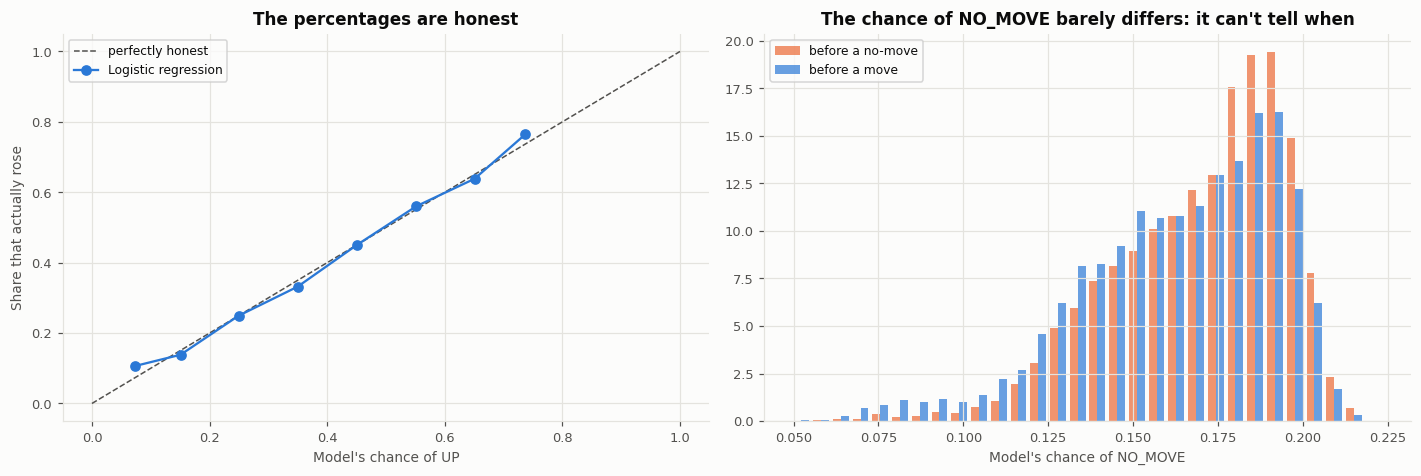

Chance of NO_MOVE on the test days: 5% to 22% (typical 17%); typical before real no-moves 17.6% vs before moves 16.8%


Input,Meaning,Weight (UP vs DOWN),Odds multiplier per typical step,In plain words
OBI_Level1,"Order-book imbalance at the best price: (bid size − ask size) ÷ total; +1 all buyers, −1 all sellers",+0.873,2.39,"With more buyers than sellers waiting at the best price, a rise is more likely: odds × 2.39 per typical step"
Spread_ticks,Spread in ticks of ₹0.05,-0.298,0.74,"With a wider gap between buying and selling prices, a fall is more likely: odds × 0.74 per typical step"
OBI_L2,Same imbalance at the second-best price level,+0.248,1.28,"With more buyers than sellers at the second-best price, a rise is more likely: odds × 1.28 per typical step"
Order_Arrival_Rate,How fast new orders arrive (given),+0.113,1.12,"With new orders arriving faster, a rise is more likely: odds × 1.12 per typical step"
Cancellation_Rate,How fast orders are being cancelled (given),-0.093,0.91,"With orders being cancelled faster, a fall is more likely: odds × 0.91 per typical step"
OBI_L3,Same imbalance at the third-best price level,+0.091,1.09,"With more buyers than sellers at the third-best price, a rise is more likely: odds × 1.09 per typical step"
Past_ret_5,Mid-price change over the stock's last 5 events,-0.023,0.98,The price having risen over the last 5 moments: almost no effect once the others are known (odds × 0.98)
Past_ret_10,Mid-price change over the stock's last 10 events,+0.012,1.01,The price having risen over the last 10 moments: almost no effect once the others are known (odds × 1.01)
Signed_volume,"Last trade's volume, positive for a buy, negative for a sell",+0.009,1.01,The last trade being a bigger purchase: almost no effect once the others are known (odds × 1.01)
Past_ret_1,Mid-price change since the stock's previous event,-0.002,1.00,The price having just risen: almost no effect once the others are known (odds × 1.00)


Move caught ≈ 7.09 bps × |lean| (fitted on the tuning days): a lean of 0.5 → about 3.5 bps = ₹3,546 per ₹1 crore before costs


,Typical |lean|,Move caught (bps),Spread (bps),No-move share,Move caught (₹ per ₹1 crore),Spread (₹ per ₹1 crore)
Tenth of |lean|,,,,,,
1,0.04,+0.27,1.10,20.9%,₹+267,"₹1,103"
2,0.12,+0.66,1.11,20.1%,₹+658,"₹1,113"
3,0.20,+1.08,1.14,19.0%,"₹+1,079","₹1,137"
4,0.28,+1.71,1.23,18.2%,"₹+1,715","₹1,232"
5,0.35,+2.24,1.30,17.3%,"₹+2,244","₹1,300"
6,0.41,+2.79,1.38,16.5%,"₹+2,793","₹1,375"
7,0.47,+3.31,1.40,15.3%,"₹+3,305","₹1,402"
8,0.53,+3.85,1.39,12.9%,"₹+3,848","₹1,388"
9,0.60,+4.28,1.40,14.3%,"₹+4,281","₹1,398"


Most confident tenth vs least: spread 1.77 vs 1.10 bps; no-move share 10.5% vs 20.9%


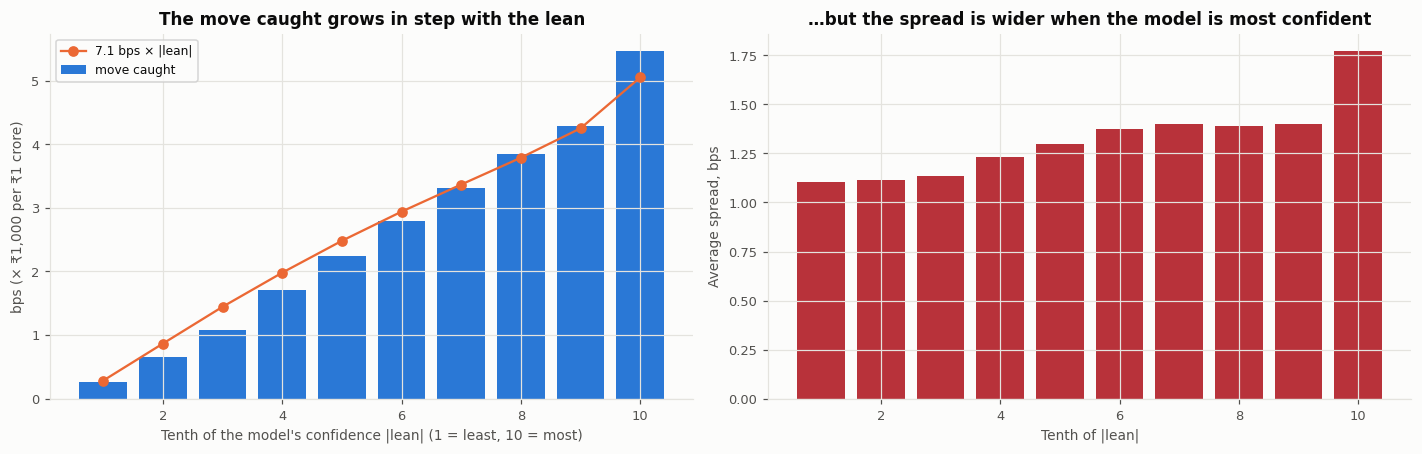

What Task 1 found,What it means for Task 2
The move caught grows in step with the lean (about 7.1 bps × |lean|),Each trade's expected gain can be estimated from the lean
The percentages are honest (step 6),That estimate can be trusted enough to weigh against costs
Spreads are wider when the model is most confident (1.77 vs 1.10 bps),A single confidence cut-off trades exactly where costs are highest: compare each moment's expected gain with that moment's own cost instead (revision of decision M7-13)
Confident moments end in no move less often (10.5% vs 20.9%),The 'don't trade' zone for weak leans also avoids most no-move trades (decision M7-11 holds)
Almost all skill is in the buyer/seller balance; logistic regression beats it slightly,Use logistic regression; show OBI alone as a comparison (decision M7-10 holds)


Example row: At the best price, about 10.6 times as many shares are waiting to be sold as bought, and the last trade was a sale. The model gives a 6% chance the price rises in the next tenth of a second, 87% that it falls and 8% that it doesn't move, so it predicts a fall. What happened: the price fell by 0.117% (₹11,750 per ₹1 crore).
Saved to module_07_hft/outputs/task1
['01_input_evidence.png', '02_obi_and_next_move.png', '03_honest_percentages_and_no_move.png', '04_what_task1_means_for_task2.png', 'FINAL_M7_T1_direction_predictions.csv', 'evidence_table.csv', 'key_numbers.json', 'model_drivers.csv', 'model_tests.csv']


In [3]:
%run notebooks/m07_task1_direction.ipynb

## 2. Task 2 — Model probability into trading signal
Runs `notebooks/m07_task2_signal.ipynb` (under a minute):
- **Test 1:** trading on the signal after the spread and Indian charges, with the cut-off chosen on the tuning days;
- **Test 2:** timing the desk's own orders;
- luck checks, by day and by stock, the cost check, and the recommendation;
- saves `outputs/task2/FINAL_M7_T2_trade_decisions.csv`.

Reads from: module_07_hft/outputs/task1
Outputs go to: module_07_hft/outputs/task2


Model from Task 1: Logistic regression; tuning moments 18,070, test moments 17,876
From Task 1's review (step 7): expected move caught ≈ 7.09 bps × |lean|; spreads are wider when the model is most confident (1.77 vs 1.10 bps)
Typical spread 1.14 bps (₹1,136 per ₹1 crore); typical move 3.88 bps (₹3,875)
Tuning days. Cost-aware rule: chosen margin +0.00 bp (most total profit)


Rule,Trades,Share of moments,Net per trade (₹ per ₹1 crore),"Net total (₹ lakh, ₹1 crore a trade)",Average spread paid (₹)
"Cost-aware, margin -0.50 bp",2942,16.3%,₹+372,₹+10.9,₹881
"Cost-aware, margin -0.25 bp",2153,11.9%,₹+523,₹+11.3,₹848
"Cost-aware, margin +0.00 bp",1479,8.2%,₹+799,₹+11.8,₹804
"Cost-aware, margin +0.25 bp",958,5.3%,"₹+1,049",₹+10.0,₹758
"Cost-aware, margin +0.50 bp",581,3.2%,"₹+1,260",₹+7.3,₹726
"Cost-aware, margin +0.75 bp",324,1.8%,"₹+1,411",₹+4.6,₹708
"Cost-aware, margin +1.00 bp",139,0.8%,"₹+1,871",₹+2.6,₹704
"Cost-aware, margin +1.50 bp",9,0.0%,₹+944,₹+0.1,₹675


For comparison, the old fixed cut-off rule: best cut-off 0.7 on the tuning days


Rule,Trades,Share of moments,Net per trade (₹ per ₹1 crore),"Net total (₹ lakh, ₹1 crore a trade)",Average spread paid (₹)
Fixed cut-off 0.40,8570,47.4%,₹-959,₹-82.1,"₹1,475"
Fixed cut-off 0.45,7096,39.3%,₹-740,₹-52.5,"₹1,495"
Fixed cut-off 0.50,5535,30.6%,₹-505,₹-27.9,"₹1,517"
Fixed cut-off 0.55,4052,22.4%,₹-259,₹-10.5,"₹1,552"
Fixed cut-off 0.60,2656,14.7%,₹-55,₹-1.5,"₹1,657"
Fixed cut-off 0.65,1592,8.8%,₹+222,₹+3.5,"₹1,819"
Fixed cut-off 0.70,867,4.8%,₹+455,₹+3.9,"₹2,139"
Fixed cut-off 0.75,460,2.5%,₹+624,₹+2.9,"₹2,486"
Fixed cut-off 0.80,198,1.1%,₹+772,₹+1.5,"₹2,953"
Fixed cut-off 0.85,22,0.1%,"₹+1,008",₹+0.2,"₹2,987"


Test days, cost-aware rule (margin +0.00 bp): 1,473 trades (8.2% of moments)


... (8 outputs left out)

Nearby margins on the test days:


Rule,Trades,Share of moments,Net per trade (₹ per ₹1 crore),"Net total (₹ lakh, ₹1 crore a trade)",Average spread paid (₹)
Margin -0.25 bp,2149,12.0%,₹+605,₹+13.0,₹852
Margin +0.00 bp,1473,8.2%,₹+700,₹+10.3,₹794
Margin +0.25 bp,934,5.2%,₹+843,₹+7.9,₹757
Margin +0.50 bp,572,3.2%,"₹+1,024",₹+5.9,₹715
Margin +1.00 bp,138,0.8%,"₹+1,526",₹+2.1,₹712


Check: how the result depends on the charges assumed (3.5 bps is the base, decision M7-06):


Charges per round trip (bps),What it would mean,If the rule knows the real cost: trades,…total (₹ lakh),If the rule assumes 3.5 but the real cost is this: total (₹ lakh)
2.500000,Only if the government cut the tax (STT alone is 2.5 bps): not realistic today,4620,₹+43.6,₹+25.0
3.000000,Only with lower exchange charges or a tax cut: unlikely,2867,₹+25.8,₹+17.7
3.500000,"The base: statutory charges, zero brokerage, every order filled at the quoted price",1473,₹+10.3,₹+10.3
4.000000,If brokerage or a slightly worse fill adds half a basis point,572,₹+3.0,₹+2.9
4.500000,If brokerage and worse fills add a full basis point,138,₹+0.7,₹-4.4


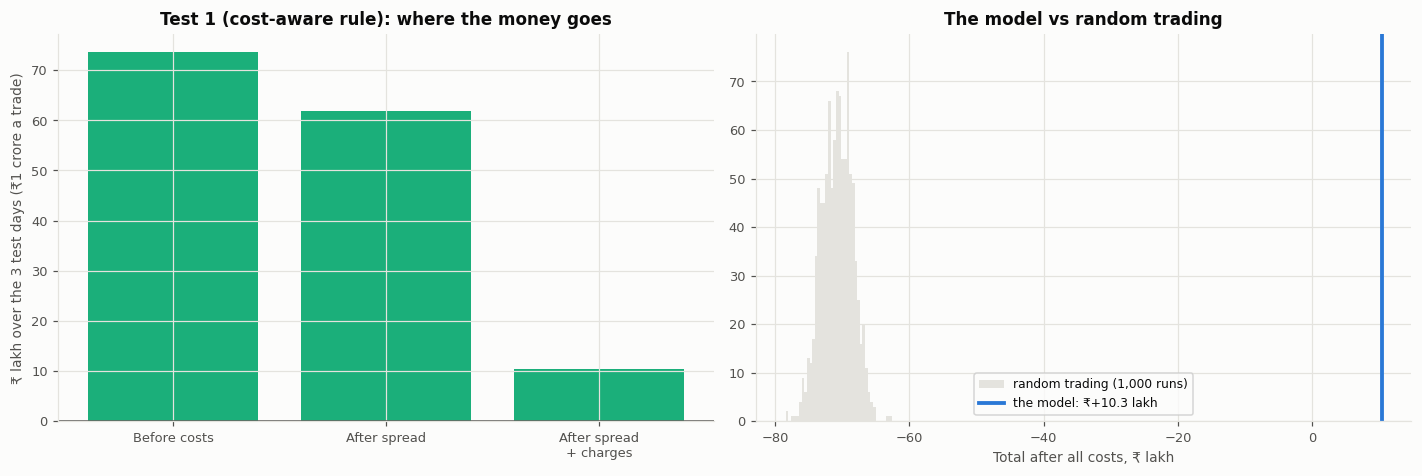

Orders delayed: 50%; delays that paid off: 69%
Average saving over ALL orders: 1.31 bps = ₹1,315 per ₹1 crore of orders


Luck check: random waiting saves ₹+0 on average (95% range ₹-30 to ₹+29); p = 0.0010
Average saving per ₹1 crore: Buy orders ₹1,332, Sell orders ₹1,298


,Saving (₹ per ₹1 crore),Typical spread (₹ per ₹1 crore)
Stock,,
NOVA01,"₹1,310","₹1,141"
NOVA02,"₹1,315",₹775
NOVA03,"₹1,275","₹2,308"
NOVA04,"₹1,357","₹1,426"
NOVA05,"₹1,233",₹646
NOVA06,"₹1,317","₹3,127"
NOVA07,"₹1,462",₹989
NOVA08,"₹1,369","₹1,730"
NOVA09,"₹1,256",₹461


Wrong delays: 31% of delays; they cost ₹3,223 on average (worst 5%: more than ₹8,353)
95% range of the average saving: ₹1,272 to ₹1,356 per ₹1 crore
Per ₹100 crore of orders a day: ₹1.31 lakh a day; ₹3.43 crore a year (261 trading days)
Waiting only when the lean is beyond 0.3: saves ₹1,119 per ₹1 crore across all orders
Waiting only when the lean is beyond 0.6: saves ₹396 per ₹1 crore across all orders
OBI alone used for timing: ₹1,287 per ₹1 crore


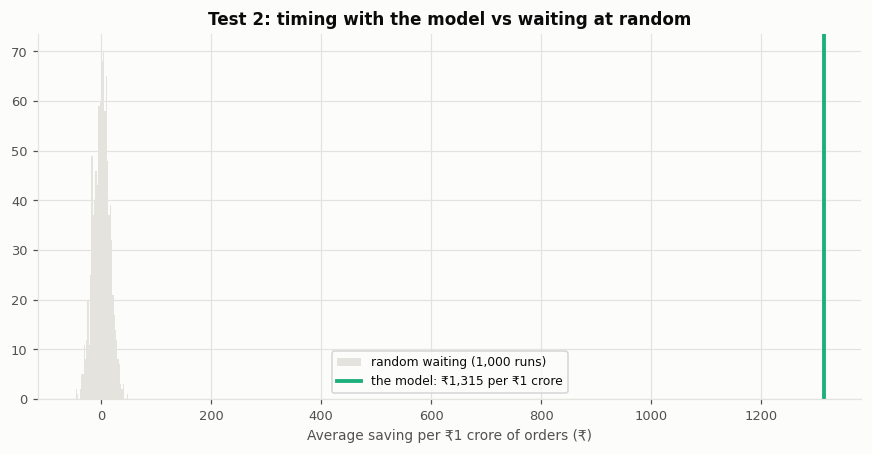

Test 1 enough value: True; Test 2 saves money: True
Recommendation: Both: time the desk's own orders now, and run the cost-aware trading rule as a measured pilot


,Category,Return per ₹ deployed (% a year),Bad-year result per ₹ (% a year)
0,High frequency trading: order timing (desk ord...,Saving of 0.013% of every ₹ of orders,0 (waiting at random saves nothing; the model ...
1,High frequency trading: order timing on Module...,0.0103,0.0
2,High frequency trading: trading pilot,"+0.007% of each ₹ traded, per trade (+₹700 per...",₹-4.4 lakh over 3 test days if real costs are ...


On Module 9's equity money, order timing is worth about 0.010% a year (₹1.03 lakh per ₹100 crore of equities): real, but too small to change an allocation.


The model expects about ₹4,198 per ₹1 crore (14% chance of a rise vs 73% of a fall), more than this moment's cost of about ₹4,150, so sell ₹1 crore and buy back a tenth of a second later. The price fell 0.033%: worth ₹+3,252; the bid–ask gap cost ₹650 and charges ₹3,500, leaving ₹-898.
The model expects a fall, so a buy order waits a tenth of a second (the price fell 0.117%, saving ₹+11,750 per ₹1 crore) and a sell order goes now.
Saved to module_07_hft/outputs/task2
['01_test1_trading.png', '02_test2_timing.png', 'FINAL_M7_T2_trade_decisions.csv', 'key_numbers.json', 'module9_inputs.csv', 'test1_rules.csv']


In [4]:
%run notebooks/m07_task2_signal.ipynb

## Final output workbook
Builds **`outputs/FINAL_M7_module_output.xlsx`**: the one file to open for this module's results (project decision P-21).
- Tabs: Read me (with a column guide) · Key numbers · Board actions · each task's final file · Hand-off to Module 9 · Decisions · Evidence index.
- Every hand-off figure is computed from the task tabs' rows, and each row says which tab, column(s) and rows it comes from.

In [5]:
%run helpers/m07_final_output.py

Saved: FINAL_M7_module_output.xlsx
                                                     Figure                                                                                                                                                                                                                                     Value                      Unit
       Can the order book predict the next 0.1-second move?                                                                                                                                                                                         Yes: right 60.6% of the time vs 42.0% by guessing share of test-day moments
                                            Recommended use                                                                                                                                                       Time the desk's own orders now; run the cost-aware trading rule as a measured pilot                         —
     